# Virtual iEEG

The work by [Grova et al. (2016)](https://onlinelibrary.wiley.com/doi/epdf/10.1002/hbm.23127) describes a methodology to compare source reconstruction with intracranial EEG and to evaluate source reconstruction in vivo. The authors project the source-reconstructed data, using a simplified forward model, onto the channel positions of the iEEG. They then compute four metrics to quantitatively evaluate the reconstruction:

1. Spatial correlation
2. Euclidean distance between maxima
3. Spatial dispersion
4. Ratio of spurious activity

This notebook implements the method proposed by Grova et al. on other datasets.

## 🧪 - Experiment setup
- `src`: Source spaces
- `i-ave`: Average intracranial recording
- `wcset`: Source estimate using wCSET method
- `sloreta`: Source estimate using sLORETA method

In [1]:
# imports
import mindmap as mm

# reader
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("intra12")

# data
src = sr.load("src")
ieeg = sr.load("i-ave", task="spk")
wcset = sr.load("stc", desc="wcset")
sloreta = sr.load("stc", desc="sloreta")

## 🧬 - Data Processing
Estimate spike generation extent and spurious areas
`extent_mask`: Mask of channels in spike extent area.
`spurious_mask`: Mask for channels in spurious area.

In [2]:
# estimate spike generation extent zone and spurious zone
extent_mask = mm.core.get_spike_extent_mask(
    ieeg.data.T, 
    perc_max_amp=0.7
)

spurious_mask = mm.core.get_spurious_mask(
    extent_mask,
    mm.analysis.eeg.get_ch_positions(ieeg),
    spurious_dist=0.01
)

Virtual electrodes: Project source reconstruction to iEEG channel positions.
`v_wcset`: virtual electrodes estimated using wCSET output
`v_sloreta`: virtual electrodes estimated using sLORETA output

In [3]:
v_wcset = mm.analysis.eeg.compute_virtual_ieeg(
    src,
    wcset,
    ieeg,
    conductivity = 0.25,
    threshold = 0.003,
)

v_sloreta = mm.analysis.eeg.compute_virtual_ieeg(
    src,
    sloreta,
    ieeg,
    conductivity = 0.25,
    threshold = 0.003,
)

Compute metrics from Grova et. al.

In [4]:
# normalize data for visualizations
ieeg_norm = mm.analysis.eeg.normalize_evoked_by_baseline(ieeg, baseline=(0, 1.0))
v_wcset_norm = mm.analysis.eeg.normalize_evoked_by_baseline(v_wcset, baseline=(0, 1.0))
v_sloreta_norm = mm.analysis.eeg.normalize_evoked_by_baseline(v_sloreta, baseline=(0,1.0))

metrics_wcset = mm.analysis.eeg.compute_grova_metrics(
    ieeg_norm,
    v_wcset_norm,
    true_extent = 0.7,
    spurious_dist = 0.01,
)

metrics_sloreta = mm.analysis.eeg.compute_grova_metrics(
    ieeg_norm,
    v_sloreta_norm,
    true_extent = 0.7,
    spurious_dist = 0.01,
)

## 📊 - Visualization
Channel position

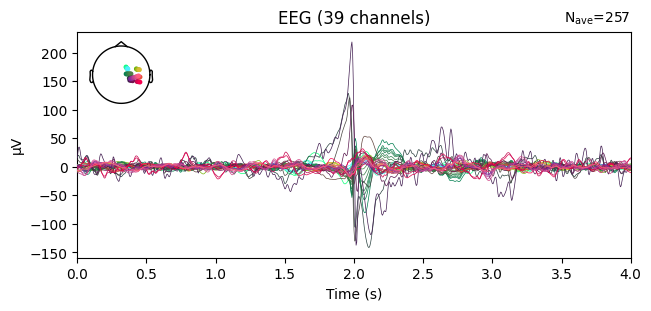

In [5]:
ieeg.plot();

In [6]:
from mindmap.viz.dispatch import plot_ieeg

plot_ieeg(src, ieeg, extent_mask, spurious_mask, subject=sr.sub, ts_params={"absolute":True}).show()

Widget(value='<iframe src="http://localhost:33737/index.html?ui=P_0x7794666d03d0_0&reconnect=auto" class="pyvi…

In [8]:
mm.viz.plot_ieeg(src, ieeg, extent_mask, spurious_mask, subject = sr.sub).show()

Widget(value='<iframe src="http://localhost:46529/index.html?ui=P_0x7cec24b0f6d0_2&reconnect=auto" class="pyvi…

Source reconstructions

In [7]:
mm.viz.plot_source_estimate(src, [wcset, sloreta], ts_params={"normalize":"robust", "absolute":True}).show()

Widget(value='<iframe src="http://localhost:37811/index.html?ui=P_0x7b71b6f70710_1&reconnect=auto" class="pyvi…

Global field power

/tmp/ipykernel_12238/43824775.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ).show()


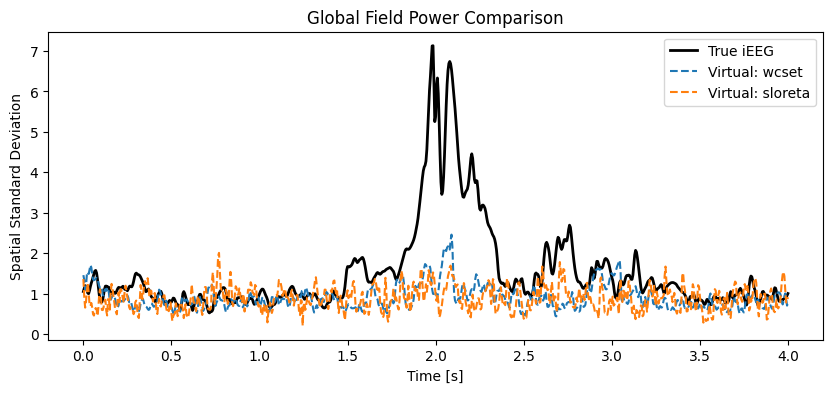

In [8]:
# plot the global field power (gfp)
mm.viz.plot_gfp_comparison(
    ieeg_norm,
    dict_of_evoked_est = {
        "wcset": v_wcset_norm,
        "sloreta": v_sloreta_norm,
    }
).show()

Individual averaged channels

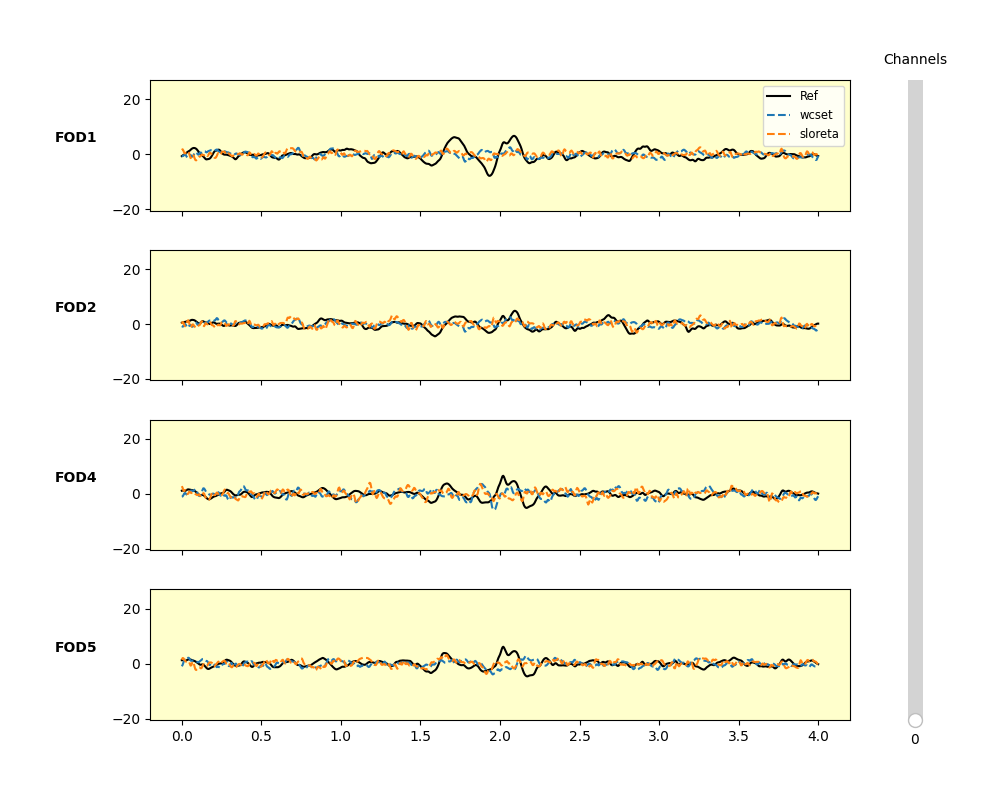

In [9]:
%matplotlib widget


# plot individual channels
_ = mm.viz.plot_channel_grid(ieeg_norm, {"wcset":v_wcset_norm, "sloreta":v_sloreta_norm}, extent_mask, spurious_mask)


In [ ]:
# binarize
ieeg_bin = mm.analysis.eeg.binarize_evoked(ieeg_norm, threshold=3, method="std", baseline=(0, 1.0))
wcset_bin = mm.analysis.eeg.binarize_evoked(v_wcset_norm, threshold=3, method="std", baseline=(0,1))
sloreta_bin = mm.analysis.eeg.binarize_evoked(v_sloreta_norm, threshold=3, method="std", baseline=(0,1))

# confusion
confusion = mm.analysis.eeg.compute_evoked_confusion()

mm.viz.plot_con


AttributeError: module 'mindmap.analysis.functional.eeg' has no attribute 'compute_evoked_confusion'

In [ ]:
import numpy as np
from scipy import signal
import mne

def compute_evoked_coherence_matrix(
    evoked1: mne.Evoked,
    evoked2: mne.Evoked,
    window: tuple[float, float] = (None, None),
    fmin: float = 0.0,
    fmax: float = np.inf,
    n_per_seg: int = None,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Compute a coherence matrix where result[i, j, f] is the coherence
    between channel i and channel j at frequency f.

    Returns
    -------
    coh_matrix: np.ndarray (n_chan_1, n_chan_2, n_freqs)
    
    freqs: np.ndarrray (n_freqs)
    """
    tmin = window[0] if window[0] is not None else evoked1.tmin
    tmax = window[1] if window[1] is not None else evoked1.tmax

    evk1 = evoked1.copy().crop(tmin=tmin, tmax=tmax)
    evk2 = evoked2.copy().crop(tmin=tmin, tmax=tmax)

    return calc_coherence_matrix(
        evk1.data,
        evk2.data,
        sfreq = evk1.info["sfreq"],
        fmin = fmin,
        fmax = fmax,
        n_per_seg = n_per_seg,
    )

def calc_coherence_matrix(
    arr1: np.ndarray,
    arr2: np.ndarray,
    sfreq: float,
    fmin: float = 0.0,
    fmax: float = np.inf,
    n_per_seg: int = None,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Compute cross-channel coherence using Welch's method.
    """
    n_ch1, n_times = arr1.shape
    n_ch2, _ = arr2.shape

    # set default window length (nperseg) if not provided
    # Coherence needs a balance between frequency resolution and variance reduction
    if n_per_seg is None:
        n_per_seg = min(n_times, 256)

    # get frequency axis first to pre-allocate
    freqs, _ = signal.coherence(arr1[0], arr2[1], fs=sfreq, nperseg=n_per_seg)

    # create frequency mask
    f_mask = (freqs >= fmin) & (freqs <= fmax)
    freqs = freqs[f_mask]

    # pre-allocate results (ch1, ch2, freqs)
    coh_matrix = np.zeros((n_ch1, n_ch2, len(freqs)))

    # compute coherence
    # iterate through ch1 and broadcast against ch2 where possible
    # but scipy.signal.coherence is usually 1-to-1
    for i in range(n_ch1):
        for j in range(n_ch2):
            _, c = signal.coherence(arr1[i], arr2[j], fs=sfreq, nperseg=n_per_seg)
            coh_matrix[i, j, :] = c[f_mask]

    return coh_matrix, freqs

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import mne

from mindmap.analysis.functional.eeg.metric import compute_evoked_rem

def plot_evoked_rem(
    evoked_ref: mne.Evoked,
    evoked_est: mne.Evoked,
    mode: str = "spatial",
    rng: tuple[float, float] = (None, None),
):
    """
    Plots a heatmap of the Relative Energy Map.
    """
    # comptue REM
    rem_map = compute_evoked_rem(evoked_ref, evoked_est, mode=mode, rng=rng)

    # extent
    times = evoked_ref.times
    mask = (times >= (rng[0] or times[0])) & (times <= (rng[1] or times[-1]))
    crop_times = times[mask]

    extent = [crop_times[0], crop_times[-1], 0, rem_map.shape[0]]

    fig, ax = plot_rem(
        rem_map,
        extent = extent,
        title = f"Relative Energy Map - {mode.capitalize()} Normalization",
        label = f"Relative Energy ({mode} normalized)",
    )

    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Channels (Index)")

    return fig, ax

def plot_rem(
    rem = np.ndarray,
    extent: list = None,
    title: str = "Relative Energy Map",
    label: str = "Relative Energy",
):
    """Generic Heatmap plotter for REM array."""
    fig, ax = plt.subplots(figsize=(12, 6))

    im = ax.imshow(
        rem,
        aspect = "auto",
        origin = "lower",
        extent = extent,
        cmap = "magma",
    )

    plt.colorbar(im, label=label)
    ax.set_title(title)
    
    return fig, ax